## Creating the dataset

In [1]:
from sklearn.datasets import make_regression

In [24]:
# 2. Regression dataset with noise
X_reg, y_reg = make_regression(
    n_samples=100, 
    n_features=1, 
    noise=15.0,   # modify the correlation between X and y by adding noise to the target variable
    random_state=42
)

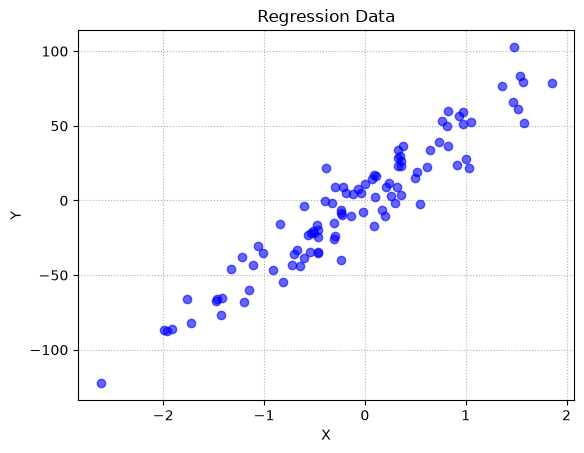

In [25]:
import matplotlib.pyplot as plt

plt.plot(X_reg, y_reg, 'o', color='blue', alpha=0.6)
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(ls=":")
plt.title('Regression Data')
plt.show()

## Creating the model

In [26]:
import keras
import numpy as np

In [27]:
model = keras.Sequential([
    keras.layers.Input(shape=(1,), dtype="float32"),
    keras.layers.Dense(units=1)
])

model.compile(optimizer="sgd", loss="mean_squared_error")

history = model.fit(X_reg, y_reg, epochs=500, verbose=1)

Epoch 1/500


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1744.0280  
Epoch 2/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1535.4968 
Epoch 3/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 1367.5575 
Epoch 4/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1227.9263 
Epoch 5/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1082.4047
Epoch 6/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 989.7584 
Epoch 7/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 874.5638
Epoch 8/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 759.7465 
Epoch 9/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 697.3617
Epoch 10/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 637.8671 
Epoch 11/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 577.8730  
Epoch 12/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 535.8805 
Epoch 13/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 502.1964 
Epoch 14/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 469.3101 
Epoch 15/500
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 434

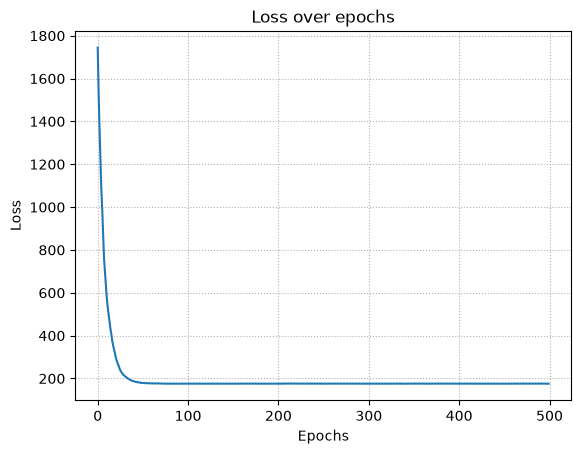

In [28]:
plt.plot(history.history["loss"])
#plt.plot(history.history["val_loss"], 'r--')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss over epochs")
plt.grid(ls=":")
plt.show()

In [29]:
y_pred = model.predict(X_reg, verbose=0).reshape(-1)

In [30]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = mean_squared_error(y_reg, y_pred)
mae = mean_absolute_error(y_reg, y_pred)

print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

Mean Squared Error (MSE): 175.6361
Mean Absolute Error (MAE): 10.6615


In [31]:
from sklearn.metrics import r2_score
r2 = r2_score(y_reg, y_pred)
print(f"R-squared (using sklearn): {r2:.4f}")

R-squared (using sklearn): 0.9069


## Creating the linear regressor

In [32]:
# y = mx+b

m = model.layers[0].get_weights()[0][0][0]
b = model.layers[0].get_weights()[1][0]

print(f"Slope (m): {m:.4f}")
print(f"Intercept (b): {b:.4f}")

Slope (m): 45.7542
Intercept (b): 1.8598


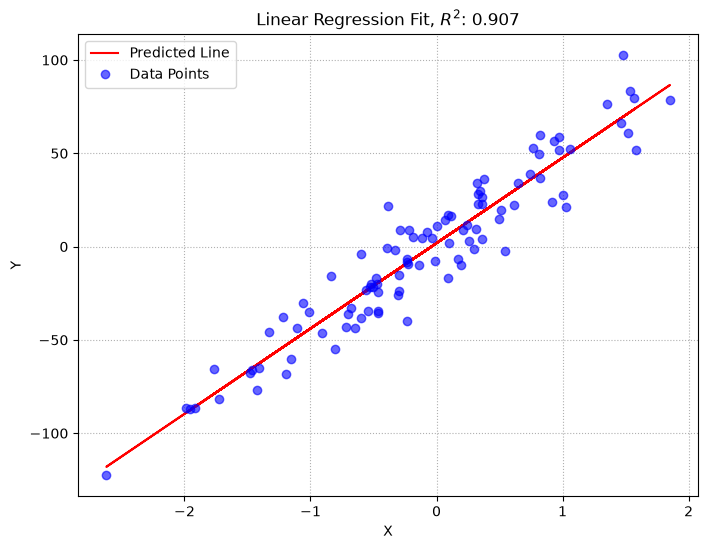

In [36]:
y_linear = m*X_reg+b

plt.figure(figsize=(8, 6))
plt.plot(X_reg, y_linear, 'r-', label='Predicted Line')
plt.plot(X_reg, y_reg, 'o', color='blue', alpha=0.6, label='Data Points')
plt.xlabel('X')
plt.ylabel('Y')
plt.title(f'Linear Regression Fit, $R^2$: {r2:.3f}')
plt.legend()
plt.grid(ls=":")
plt.show()

In [39]:
x_test = -2
print(f"Prediction at x={x_test}, y={model.predict(np.array([[x_test]], dtype=np.float32), verbose=0)[0, 0]}:")

Prediction at x=-2, y=-89.64854431152344:
